# 04 — GME daily gas prices

Builds the **daily gas price** series from the GME gas market (MGP-GAS), used as the fuel-cost feature and in the spark spread.

- **Input:** `data/raw/gme_gas/Annotermico*.zip` (thermal years Oct → Sep)
- **Output:** `data/processed/gas_mgp_daily_2020_2025.parquet` (1,826 days, no gaps or duplicates)
- **Key points:** the gas price peaks at 312 €/MWh at the end of August 2022. To avoid look-ahead, all hours of day D use the gas price of day D-1 (known at 12:00 D-1).

In [1]:
# 04_gas_ingestion.ipynb - cell 1: setup and file discovery
import io
import zipfile
from pathlib import Path

import pandas as pd

RAW_GAS_DIR = Path("../data/raw/gme_gas")
PROCESSED_DIR = Path("../data/processed")

# Thermal-year ZIP names are not uniform (an extra underscore shows up from
# 2024/25 onwards), so we discover them instead of hard-coding the list.
gas_zips = sorted(RAW_GAS_DIR.glob("*.zip"))
print(f"{len(gas_zips)} thermal-year archives found\n")

for zip_path in gas_zips:
    with zipfile.ZipFile(zip_path) as z:
        inner_files = z.namelist()
    print(f"{zip_path.name:35s} -> {inner_files}")

5 thermal-year archives found

Annotermico2020-2021.zip            -> ['Annotermico2020-2021_09.xlsx']
Annotermico2021-2022.zip            -> ['Annotermico_2021-2022_09.xlsx']
Annotermico2022-2023.zip            -> ['Annotermico_2022-2023_09.xlsx']
Annotermico2023-2024.zip            -> ['Annotermico_2023-2024_09.xlsx']
Annotermico2024-2025.zip            -> ['Annotermico_2024-2025_09.xlsx']


In [3]:
# 04_gas_ingestion.ipynb - cell 2: inspect sheet names and raw header layout

def load_workbook(zip_path):
    """Return a pandas ExcelFile for the single .xlsx stored inside the ZIP.
    The archive is never extracted: data/raw stays immutable and the pipeline
    reproducible. The file is read into memory because openpyxl needs a
    seekable buffer."""
    with zipfile.ZipFile(zip_path) as z:
        xlsx_name = next(n for n in z.namelist() if n.lower().endswith(".xlsx"))
        blob = io.BytesIO(z.read(xlsx_name))
    return pd.ExcelFile(blob, engine="openpyxl")


# Show every column: the sheet width is one of the things we want to check,
# so we must not constrain it with usecols.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

for zip_path in gas_zips:
    xls = load_workbook(zip_path)

    # The sheet we want is the continuous-trading day-ahead gas market.
    # Match loosely: the exact spelling may drift across thermal years.
    candidates = [s for s in xls.sheet_names if "MGP" in s.upper() and "GAS" in s.upper()]

    print("=" * 78)
    print(zip_path.name)
    print("  sheets:", xls.sheet_names)
    print("  MGP-GAS candidates:", candidates)

    # Read the top-left corner with no header parsing at all, to see the
    # multi-row header exactly as it sits in the file.
    raw_head = pd.read_excel(xls, sheet_name=candidates[0], header=None, nrows=8)
    print(f"  shape of the first 8 rows: {raw_head.shape}")
    print(raw_head.to_string(), "\n")

Annotermico2020-2021.zip
  sheets: ['Legenda', 'MGP-GAS - Negoziazione continua', 'MGP-Gas- Comparto AGS', 'MI-GAS - Negoziazione continua', 'MI-Gas- Comparto AGS', 'MPL', 'MGS', 'DATI SBILANCIAMENTO']
  MGP-GAS candidates: ['MGP-GAS - Negoziazione continua', 'MGP-Gas- Comparto AGS']
  shape of the first 8 rows: (8, 4)
                                  0                                                1                 2      3
0  Giorno gas/\nGas day\n(YYYYMMDD)  Prezzo medio ponderato/\nWeighted average price  Volumi/\nVolumes    NaN
1                               NaN                                              NaN               NaN    NaN
2                               NaN                                              NaN               NaN    NaN
3                               NaN                                              NaN               NaN    NaN
4                               NaN                                              NaN               NaN    NaN
5                  

In [4]:
# 04_gas_ingestion.ipynb - cell 3: single thermal-year reader and structural checks

# Sheet layout confirmed identical on all five thermal years:
#   row 0 -> column names (merged cell: "Volumi" spans the MW and MWh columns)
#   rows 1-4 -> empty
#   row 5 -> units (€/MWh, MW, MWh)
#   row 6 onwards -> data
GAS_HEADER_ROWS = 6
GAS_COLUMNS = ["gas_day", "price_eur_mwh", "volume_mw", "volume_mwh"]
SHEET_KEYWORDS = ("MGP", "GAS", "NEGOZIAZIONE")


def find_mgp_gas_sheet(xls):
    """Locate the continuous-trading day-ahead gas sheet. We require the match
    to be unique: if a future file renames the sheet we want a loud failure,
    not a silently wrong sheet (the AGS segment is a different market)."""
    matches = [s for s in xls.sheet_names if all(k in s.upper() for k in SHEET_KEYWORDS)]
    if len(matches) != 1:
        raise ValueError(f"expected exactly 1 MGP-GAS sheet, found {matches}")
    return matches[0]


def read_thermal_year(zip_path):
    """Read one thermal-year archive into a raw DataFrame. No type coercion and
    no cleaning here on purpose: we want to see what the file actually contains
    before deciding how to fix it."""
    xls = load_workbook(zip_path)
    sheet = find_mgp_gas_sheet(xls)
    df = pd.read_excel(
        xls,
        sheet_name=sheet,
        header=None,
        skiprows=GAS_HEADER_ROWS,
        names=GAS_COLUMNS,
    )
    # Keep provenance: which archive each row came from. Useful when two
    # thermal years disagree on an overlapping day.
    df["source_file"] = zip_path.name
    return df


for zip_path in gas_zips:
    df = read_thermal_year(zip_path)
    print("=" * 78)
    print(f"{zip_path.name} -> shape {df.shape}")
    print("  dtypes:", {c: str(t) for c, t in df.dtypes.items()})
    print("  NaNs per column:", df.isna().sum().to_dict())
    print("  duplicated gas_day:", int(df['gas_day'].duplicated().sum()))
    print("  first / last gas_day:", df['gas_day'].iloc[0], "/", df['gas_day'].iloc[-1])
    print("  last 3 rows:")
    print(df.tail(3).to_string(), "\n")

Annotermico2020-2021.zip -> shape (365, 5)
  dtypes: {'gas_day': 'int64', 'price_eur_mwh': 'float64', 'volume_mw': 'int64', 'volume_mwh': 'int64', 'source_file': 'str'}
  NaNs per column: {'gas_day': 0, 'price_eur_mwh': 0, 'volume_mw': 0, 'volume_mwh': 0, 'source_file': 0}
  duplicated gas_day: 0
  first / last gas_day: 20201001 / 20210930
  last 3 rows:
      gas_day  price_eur_mwh  volume_mw  volume_mwh               source_file
362  20210928         75.930       4263      102312  Annotermico2020-2021.zip
363  20210929         80.851       4460      107040  Annotermico2020-2021.zip
364  20210930         81.900       4005       96120  Annotermico2020-2021.zip 

Annotermico2021-2022.zip -> shape (365, 5)
  dtypes: {'gas_day': 'int64', 'price_eur_mwh': 'float64', 'volume_mw': 'int64', 'volume_mwh': 'int64', 'source_file': 'str'}
  NaNs per column: {'gas_day': 0, 'price_eur_mwh': 0, 'volume_mw': 0, 'volume_mwh': 0, 'source_file': 0}
  duplicated gas_day: 0
  first / last gas_day: 2021100

In [5]:
# 04_gas_ingestion.ipynb - cell 4: concatenate thermal years and validate

# Conversion factor for Italian natural gas: higher heating value is about
# 38.1 MJ/Sm3, i.e. ~0.0106 MWh per cubic metre. Used only to read the traded
# volumes in physical units - it never enters the model.
MWH_PER_CUBIC_METRE = 0.0106

gas_raw = pd.concat([read_thermal_year(p) for p in gas_zips], ignore_index=True)

# The gas day is a calendar label for a 24h delivery window (06:00 to 06:00
# local time), not an instant, so it stays timezone-naive here. Expanding it
# into hourly UTC timestamps is a job for 05_dataset.
gas_raw["gas_day"] = pd.to_datetime(gas_raw["gas_day"], format="%Y%m%d", errors="raise")
gas_raw = gas_raw.sort_values("gas_day").reset_index(drop=True)

# --- continuity invariants ------------------------------------------------
full_range = pd.date_range(gas_raw["gas_day"].min(), gas_raw["gas_day"].max(), freq="D")
missing_days = full_range.difference(gas_raw["gas_day"])

print(f"rows: {len(gas_raw)} | calendar days in range: {len(full_range)}")
print(f"range: {gas_raw['gas_day'].min().date()} -> {gas_raw['gas_day'].max().date()}")
print("duplicated gas_day:", int(gas_raw["gas_day"].duplicated().sum()))
print("missing gas_day:", [d.date() for d in missing_days])

# volume_mw should be exactly volume_mwh / 24. If it is, it carries no
# information and we drop it instead of keeping two spellings of one number.
vol_gap = (gas_raw["volume_mw"] - gas_raw["volume_mwh"] / 24).abs()
print("max |volume_mw - volume_mwh/24|:", vol_gap.max())

# --- liquidity: the weak point of using MGP-GAS as a PSV proxy ------------
# Italian daily gas demand is roughly 170 million cubic metres, so this column
# says how thin the exchange was in each period of the sample.
gas_raw["volume_mcm"] = gas_raw["volume_mwh"] / MWH_PER_CUBIC_METRE / 1e6

print("\nzero-price days:", int((gas_raw["price_eur_mwh"] == 0).sum()))
print("zero-volume days:", int((gas_raw["volume_mwh"] == 0).sum()))
print("\ntraded volume [million m3/day] by thermal year:")
print(gas_raw.groupby("source_file")["volume_mcm"].describe()[["min", "50%", "max"]].round(1).to_string())

rows: 1826 | calendar days in range: 1826
range: 2020-10-01 -> 2025-09-30
duplicated gas_day: 0
missing gas_day: []
max |volume_mw - volume_mwh/24|: 0.0

zero-price days: 0
zero-volume days: 0

traded volume [million m3/day] by thermal year:
                          min   50%   max
source_file                              
Annotermico2020-2021.zip  2.2   9.0  32.7
Annotermico2021-2022.zip  6.9  16.9  49.1
Annotermico2022-2023.zip  5.2  20.6  48.7
Annotermico2023-2024.zip  7.2  24.4  53.1
Annotermico2024-2025.zip  6.2  32.2  66.8


{'gas_day': dtype('<M8[us]'), 'price_eur_mwh': dtype('float64'), 'volume_mwh': dtype('int64'), 'volume_mcm': dtype('float64')}

price summary [EUR/MWh]:
count    1826.00
mean       56.54
std        44.65
min        11.05
25%        32.14
50%        39.69
75%        66.72
max       312.45

5 most expensive gas days:
   gas_day  price_eur_mwh  volume_mwh  volume_mcm
2022-08-26        312.448      175656   16.571321
2022-08-27        305.387      144576   13.639245
2022-08-29        292.106      275568   25.996981
2022-08-25        287.778      120744   11.390943
2022-08-28        285.681      263208   24.830943

5 cheapest gas days:
   gas_day  price_eur_mwh  volume_mwh  volume_mcm
2020-10-03         11.048       89832    8.474717
2020-10-04         11.064      103728    9.785660
2020-10-11         11.619      146016   13.775094
2020-10-10         11.802      139728   13.181887
2020-10-05         12.019       43032    4.059623


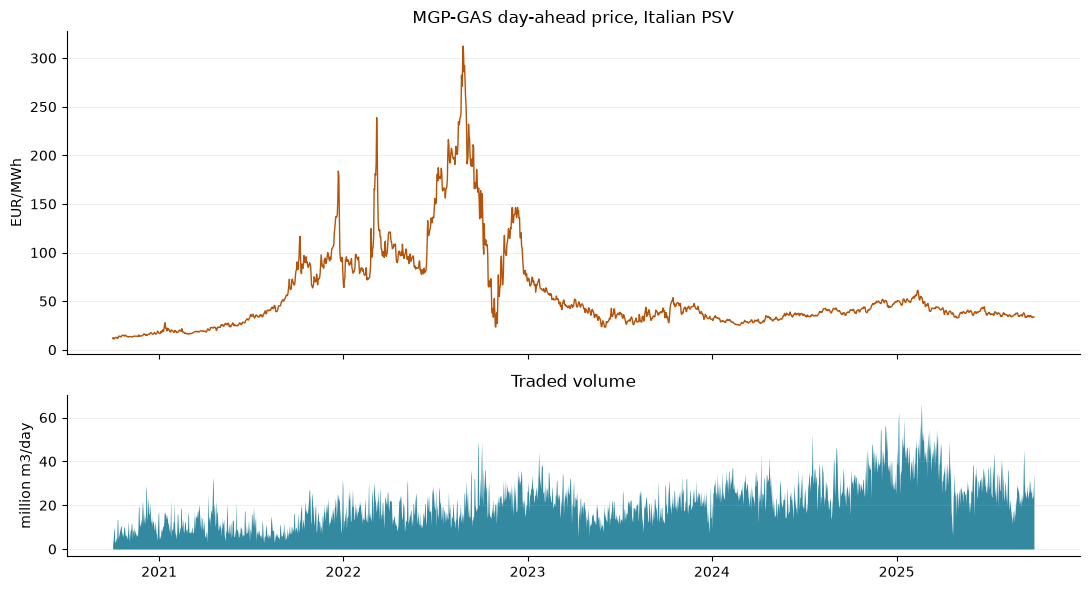

In [6]:
# 04_gas_ingestion.ipynb - cell 5: final tidy-up and visual sanity check
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# volume_mw is exactly volume_mwh / 24 (verified: max difference 0.0), so it
# carries no information. source_file is recoverable from the date. Both go.
gas_daily = gas_raw.drop(columns=["volume_mw", "source_file"]).copy()

print(gas_daily.dtypes.to_dict())
print("\nprice summary [EUR/MWh]:")
print(gas_daily["price_eur_mwh"].describe().round(2).to_string())

# Look at the extremes by name: the 2022 peak is the European gas crisis, and
# the minimum says how low the series actually went.
print("\n5 most expensive gas days:")
print(gas_daily.nlargest(5, "price_eur_mwh").to_string(index=False))
print("\n5 cheapest gas days:")
print(gas_daily.nsmallest(5, "price_eur_mwh").to_string(index=False))

# Two stacked panels sharing the time axis. Never two y-scales on one plot:
# price and volume are different quantities, and overlaying them invites the
# false reading that they move together.
fig, (ax_price, ax_volume) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

ax_price.plot(gas_daily["gas_day"], gas_daily["price_eur_mwh"], linewidth=1.0, color="#B45309")
ax_price.set_ylabel("EUR/MWh")
ax_price.set_title("MGP-GAS day-ahead price, Italian PSV")

ax_volume.fill_between(
    gas_daily["gas_day"], gas_daily["volume_mcm"], linewidth=0, color="#0E7490", alpha=0.85
)
ax_volume.set_ylabel("million m3/day")
ax_volume.set_title("Traded volume")

for ax in (ax_price, ax_volume):
    ax.grid(axis="y", linewidth=0.5, alpha=0.3)   # recessive grid, never dominant
    ax.spines[["top", "right"]].set_visible(False)

ax_volume.xaxis.set_major_locator(mdates.YearLocator())
ax_volume.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
plt.show()

In [7]:
# 04_gas_ingestion.ipynb - cell 6: persist and verify the round-trip
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out_path = PROCESSED_DIR / "gas_mgp_daily_2020_2025.parquet"
gas_daily.to_parquet(out_path, index=False)

# Read it back and check it survived. A processed file is only trustworthy if
# the next notebook can start from it without this kernel being alive - same
# principle you applied when 02_eda restarted from the parquet instead of 01.
check = pd.read_parquet(out_path)
assert len(check) == len(gas_daily), "row count changed on round-trip"
assert check["gas_day"].dtype == gas_daily["gas_day"].dtype, "gas_day dtype changed"
assert check["price_eur_mwh"].equals(gas_daily["price_eur_mwh"]), "prices changed"

print(f"saved {len(check)} rows to {out_path}")
print(check.head(3).to_string(index=False))

saved 1826 rows to ../data/processed/gas_mgp_daily_2020_2025.parquet
   gas_day  price_eur_mwh  volume_mwh  volume_mcm
2020-10-01         12.119       23640    2.230189
2020-10-02         12.419       44712    4.218113
2020-10-03         11.048       89832    8.474717
